In [1]:
import pandas as pd
import os
import cv2
import torch
import torchvision
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torchvision import models


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


cuda


In [3]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [4]:
target_layer = model.layer4[-1].conv3

In [5]:
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])



In [6]:
# Hooks (keep structure, but reset per image)
activations = []
gradients = []

def forward_hook(module, input, output):
    activations.append(output)

def backward_hook(module, grad_in, grad_out):
    gradients.append(grad_out[0])

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

In [7]:
# Image list (multiple images)

img_dir = "/home/dbtproject/barsha/Image/test_set/Class0_Graminicola"
img_files = [f for f in os.listdir(img_dir) if f.endswith((".jpg", ".png", ".tiff"))]

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.5733], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


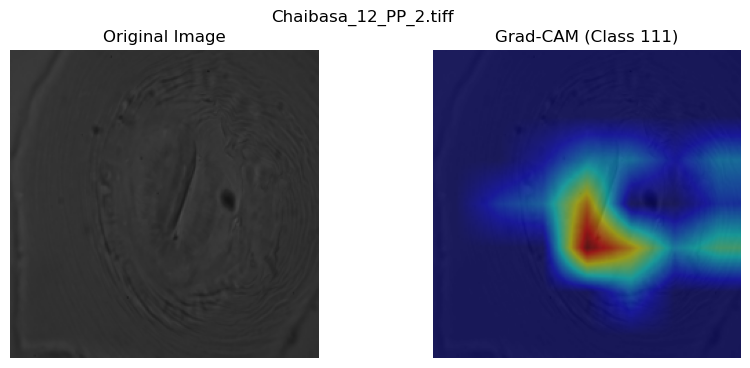

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.5367], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


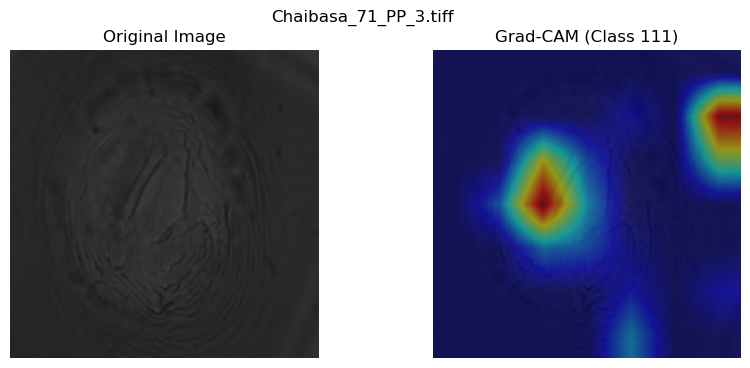

---------
torch.Size([1, 1000])
tensor([103], device='cuda:0')
tensor([6.3211], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


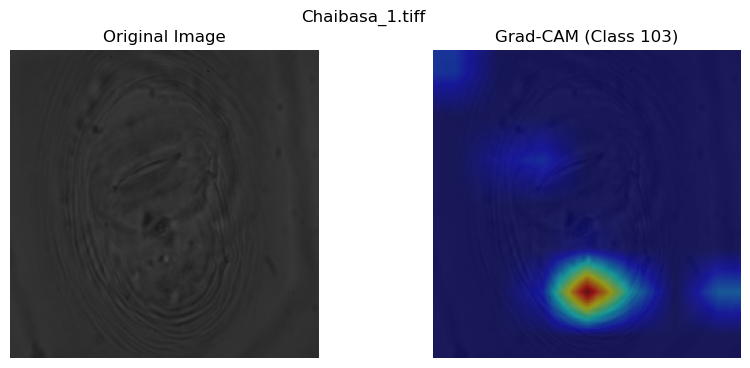

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.3109], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


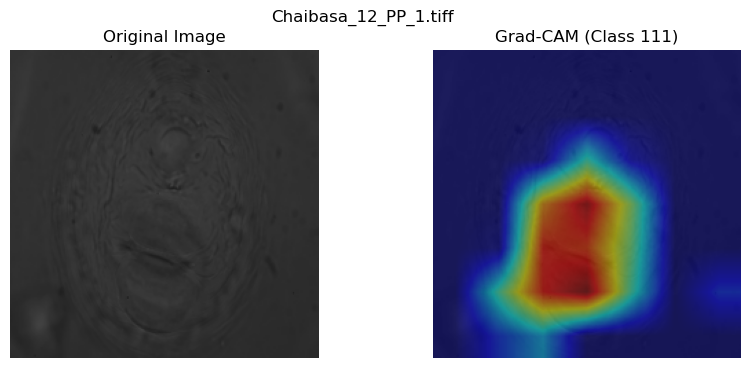

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.6919], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


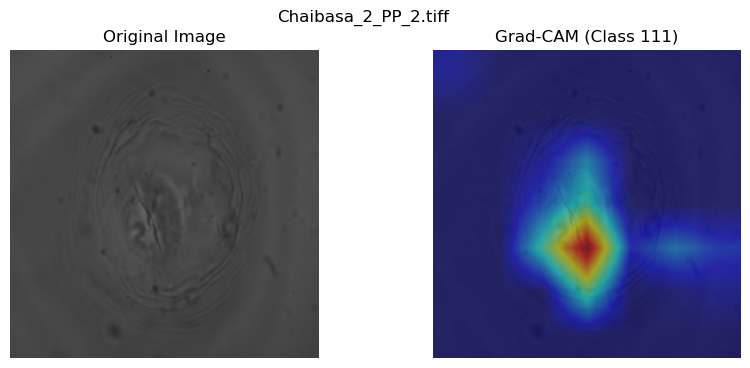

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.7959], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


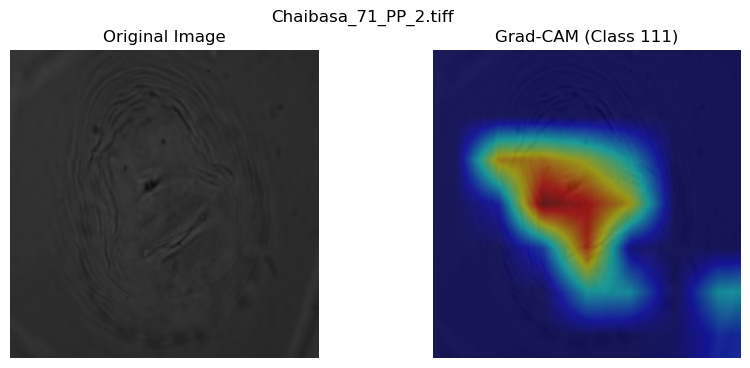

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.7598], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


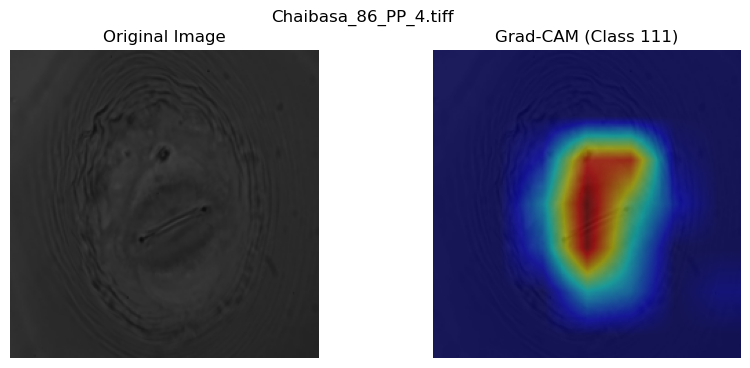

---------
torch.Size([1, 1000])
tensor([936], device='cuda:0')
tensor([5.6808], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


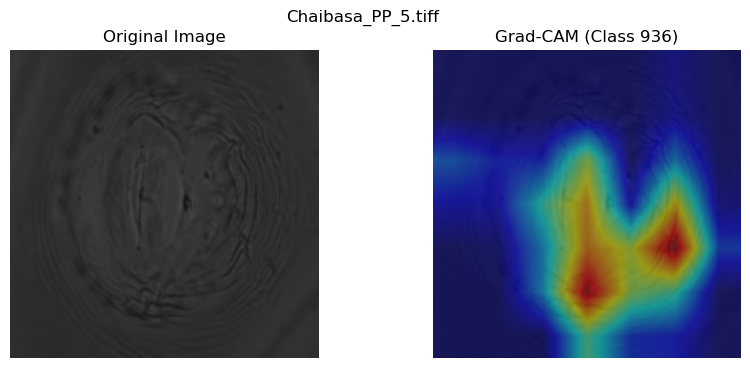

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([7.2575], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


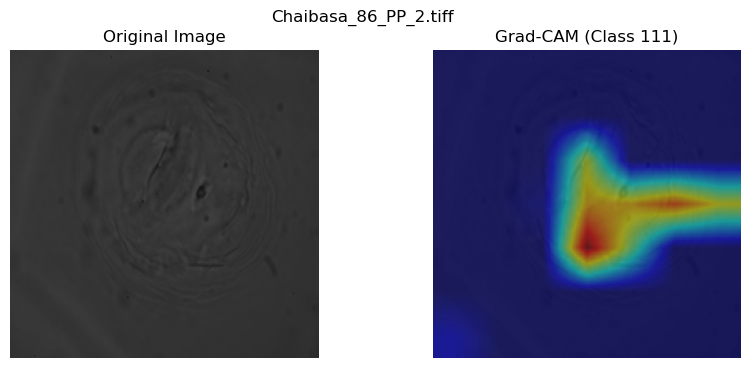

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([8.3008], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


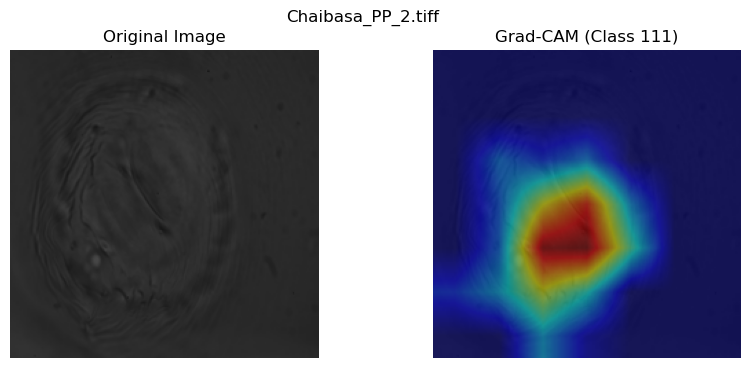

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([7.1195], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


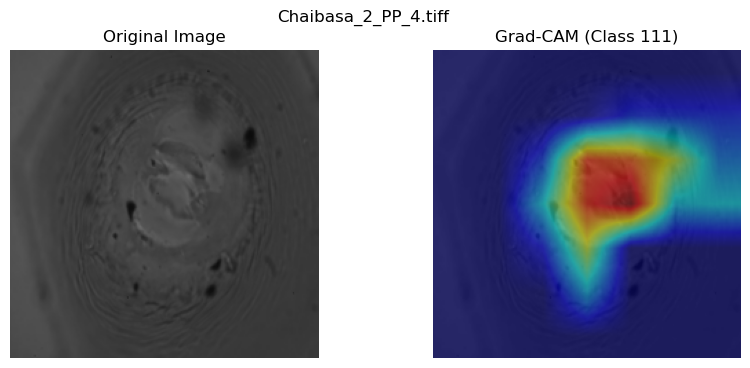

---------
torch.Size([1, 1000])
tensor([659], device='cuda:0')
tensor([5.8893], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


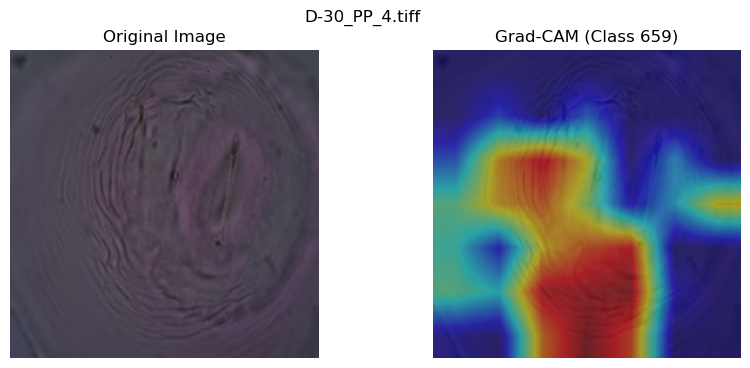

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.7045], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


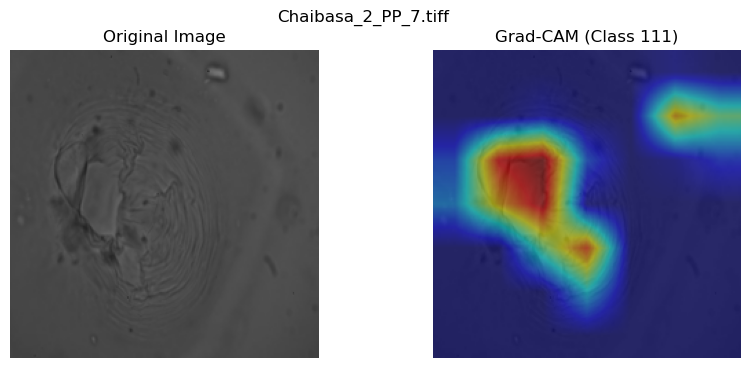

---------
torch.Size([1, 1000])
tensor([659], device='cuda:0')
tensor([5.5205], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


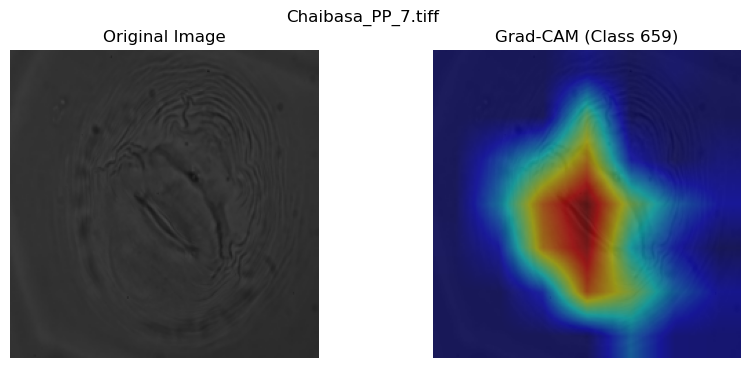

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.8222], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


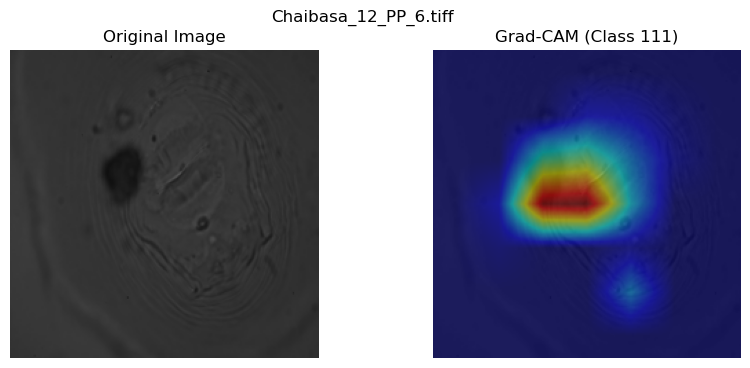

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.0207], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


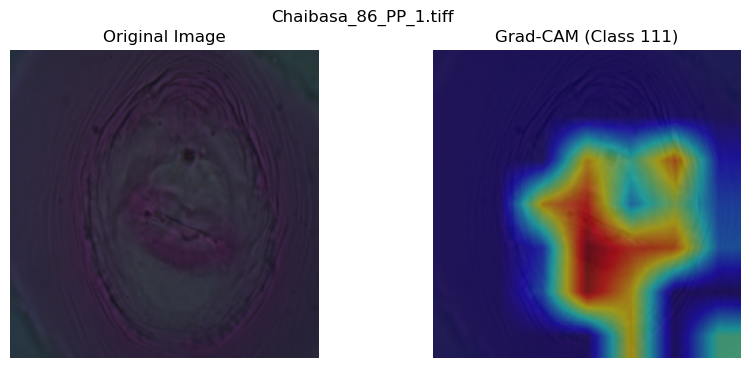

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.4963], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


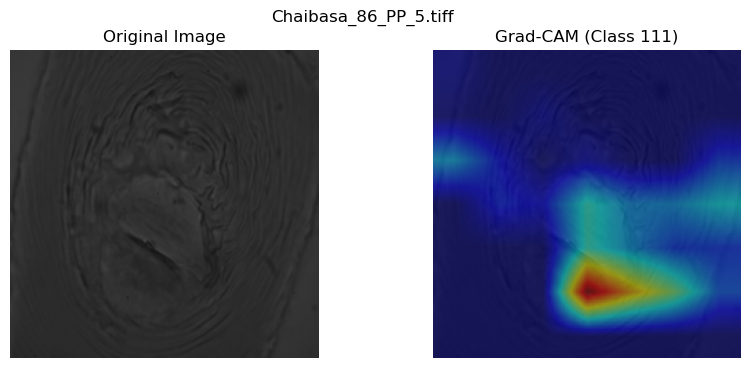

---------
torch.Size([1, 1000])
tensor([659], device='cuda:0')
tensor([5.7233], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


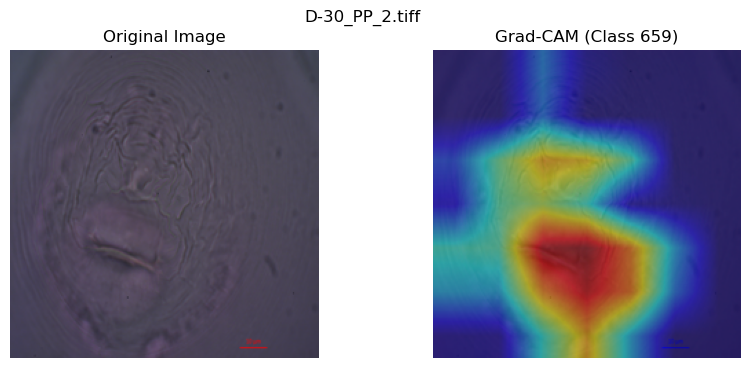

---------
torch.Size([1, 1000])
tensor([659], device='cuda:0')
tensor([6.5537], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


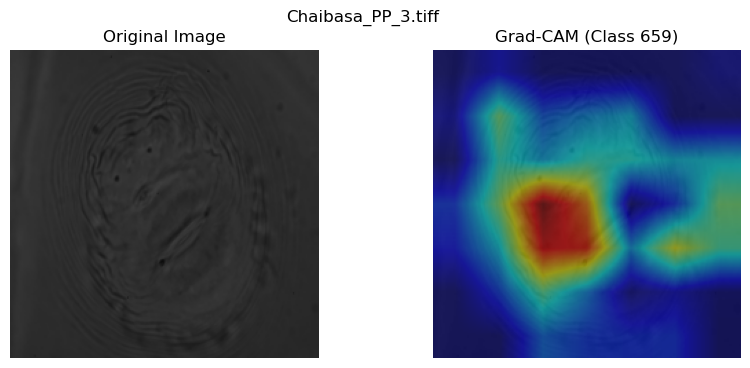

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.4858], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


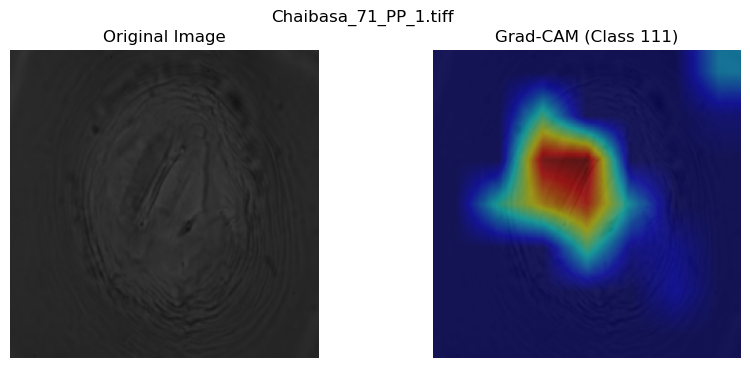

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.6303], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


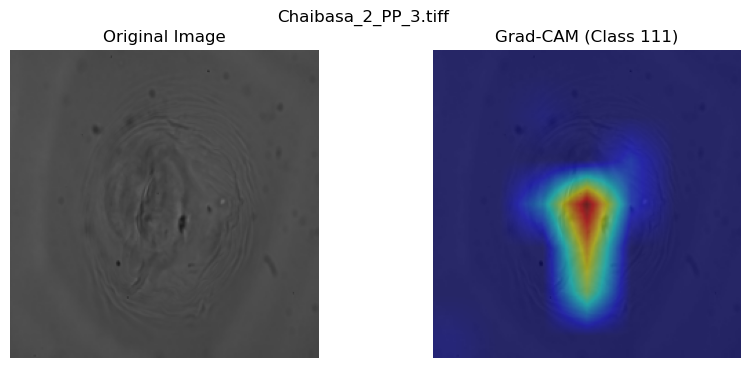

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.7339], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


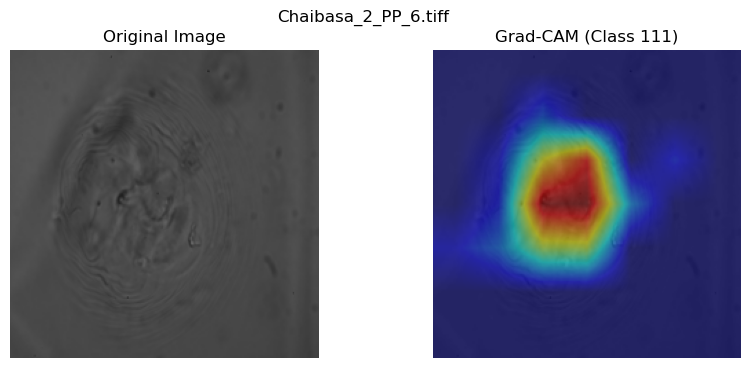

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([7.4540], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


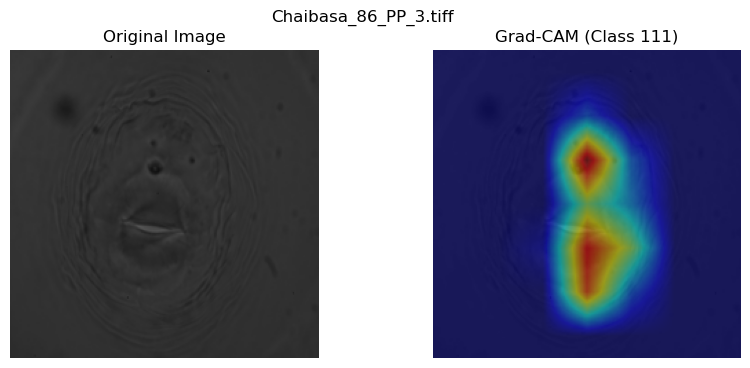

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.2828], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


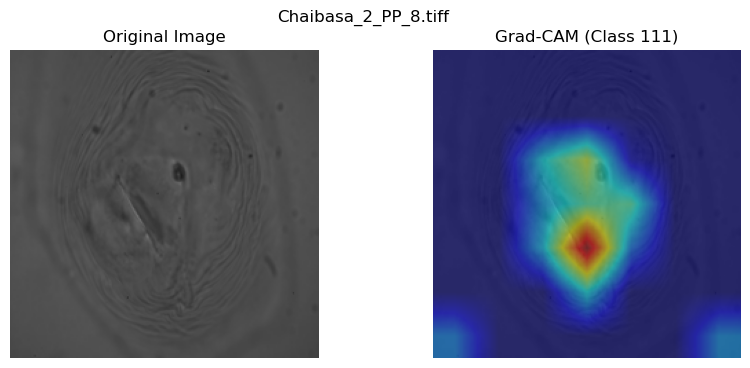

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.1169], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


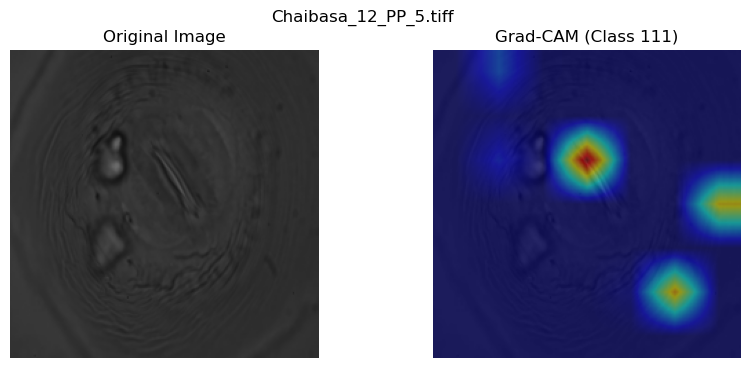

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.7654], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


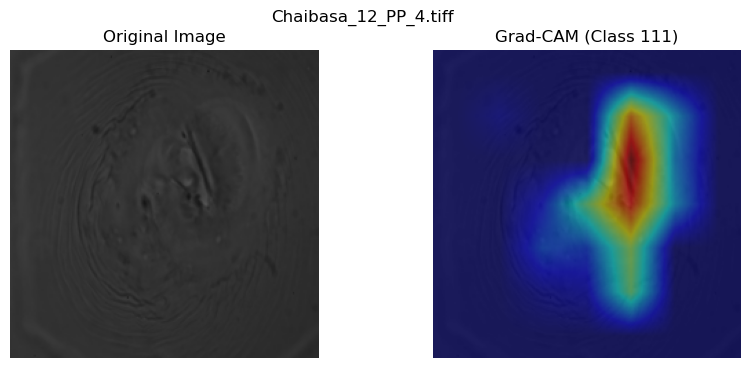

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([7.1732], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


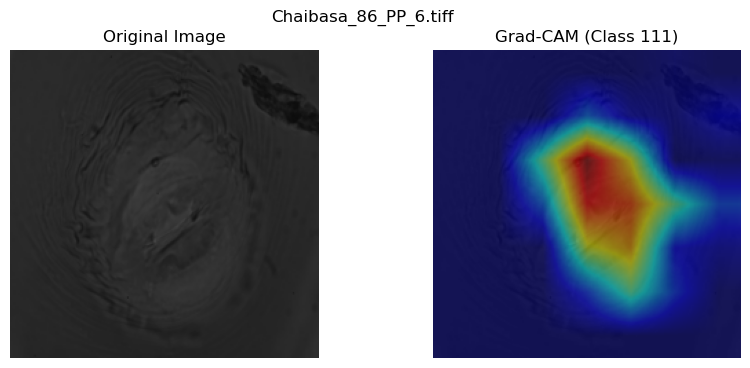

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.6648], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


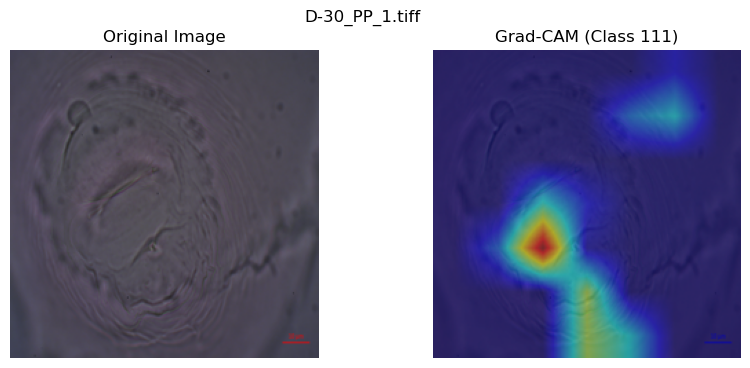

---------
torch.Size([1, 1000])
tensor([936], device='cuda:0')
tensor([5.2334], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


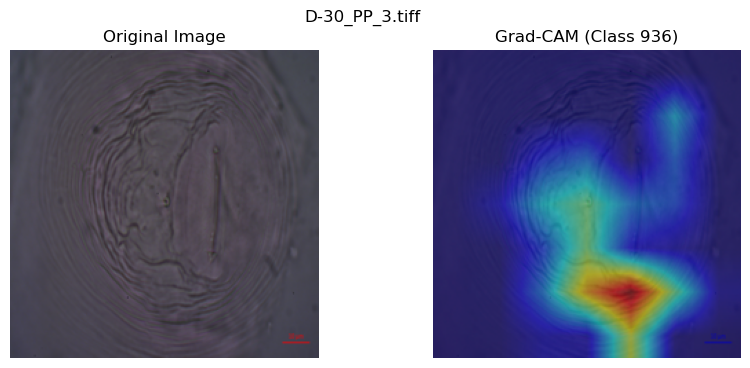

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.6047], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


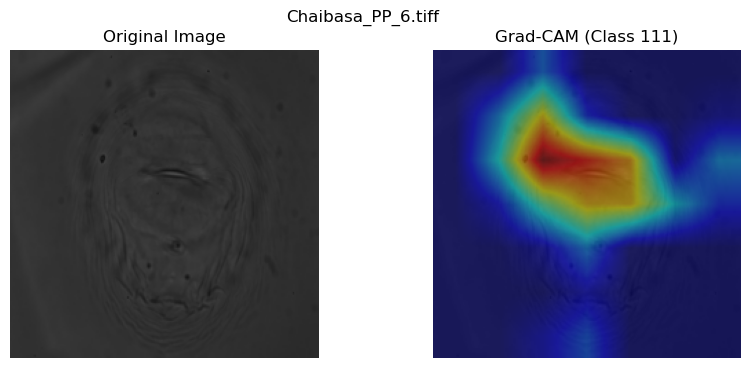

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.4935], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


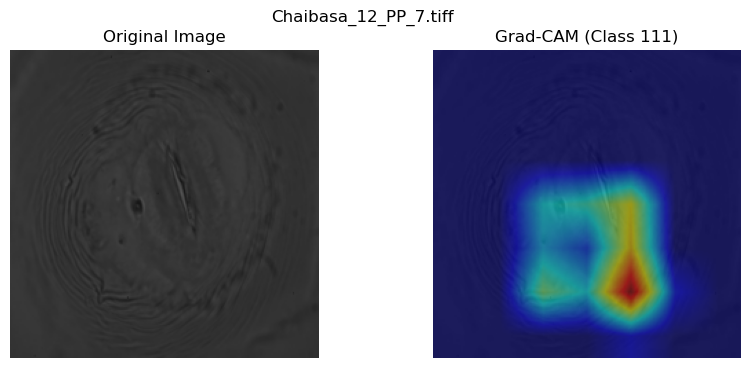

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.3959], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


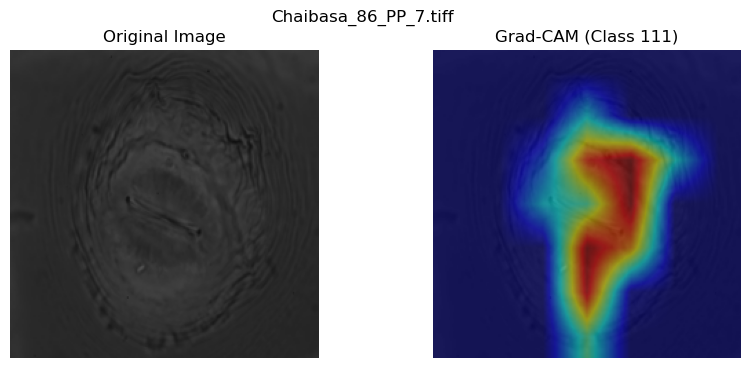

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([7.0823], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


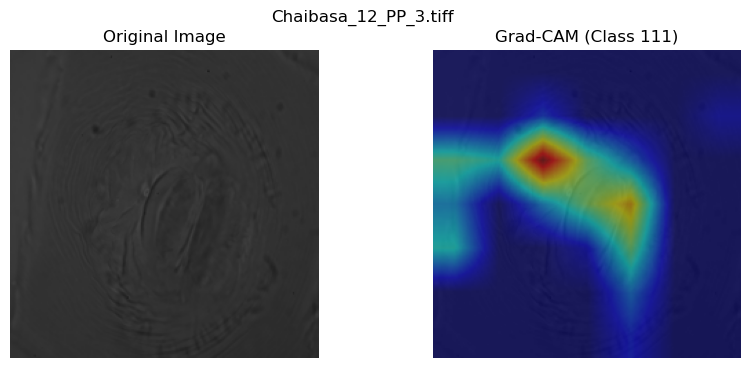

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([5.7076], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


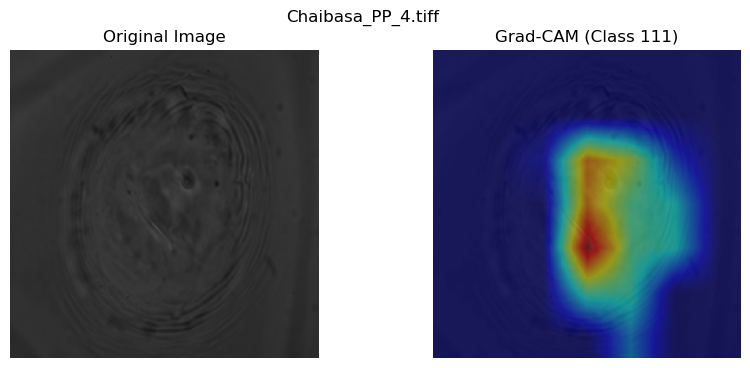

---------
torch.Size([1, 1000])
tensor([111], device='cuda:0')
tensor([6.8543], device='cuda:0', grad_fn=<IndexBackward0>)
torch.Size([2048, 7, 7]) 
 torch.Size([2048, 7, 7])


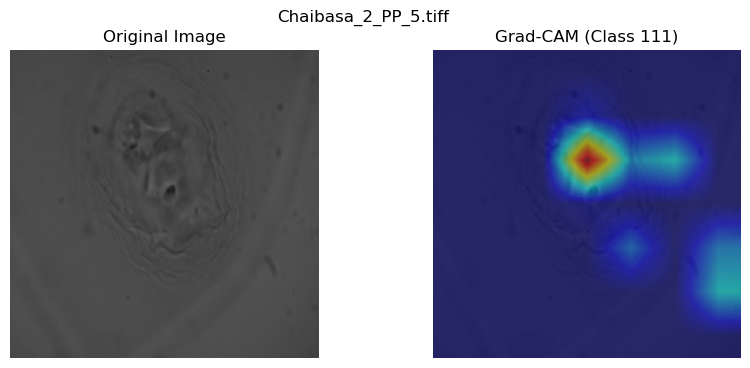

In [8]:
# Loop over images

for img_name in img_files:

    # Clear previous hooks data
    activations.clear()
    gradients.clear()

    img_path = os.path.join(img_dir, img_name)
    img = Image.open(img_path).convert("RGB")

    input_tensor = img_transform(img).unsqueeze(0).to(device)

    # -------------------------
    # Forward
    # -------------------------
    output = model(input_tensor)
    pred_class = output.argmax(dim=1)
    print('---------')
    print(output.shape)
    print(pred_class)
    print(output[0,pred_class])


    # -------------------------
    # Backward
    # -------------------------
    model.zero_grad()
    output[0, pred_class].backward()

    # -------------------------
    # Grad-CAM computation
    # -------------------------
    act = activations[0].squeeze().detach()     # [C, H, W]
    grad = gradients[0].squeeze().detach()      # [C, H, W]

    print(act.shape, '\n', grad.shape)

    weights = grad.mean(dim=(1, 2))             

    cam = torch.zeros(act.shape[1:], dtype=torch.float32).to(act.device)

    for i, w in enumerate(weights):
        cam += w * act[i]

    cam = F.relu(cam)
    cam = cam - cam.min()
    cam = cam / cam.max()

    cam = cam.detach().cpu().numpy()



    # -------------------------
    # Visualization
    # -------------------------
    heatmap = cv2.resize(cam, (224, 224))
    heatmap = cv2.applyColorMap(
        np.uint8(255 * heatmap),
        cv2.COLORMAP_JET
    )

    img_np = np.array(img.resize((224, 224)))
    overlay = cv2.addWeighted(img_np, 0.5, heatmap, 0.5, 0)
    overlay_rgb = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

    # -------------------------
    # Plot: Original vs Grad-CAM
    # -------------------------
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(img_np)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(overlay_rgb)
    plt.title(f"Grad-CAM (Class {pred_class.item()})")
    plt.axis("off")

    plt.suptitle(img_name)
    plt.show()



